# Projector inversion: specimen → detector

**Only the projector is modelled.** A small Gaussian beam starts at the specimen and passes the objective post-field, IL1, IL2, IL3 and PL1 to the detector. No condenser, source or aperture is simulated or fitted.

**Only beam shifts and tilts are used.** At each projector setting the beam is shifted by ±20 nm in X and tilted by about ±3 mrad in X and in Y at the specimen. Half the difference between each ± pair of detector centres is

$$
\Delta\bar{\mathbf{x}}_D = A\,\Delta\mathbf{x}_S + B\,\Delta\boldsymbol{\theta}_S ,
$$

where $A$ and $B$ are the position blocks of the specimen-to-detector ray matrix. Beam width and intensity are not used.

**The acquisition** reuses the projector rows of the saved calibration: 18 settings per voltage (IL1–PL1 each changed by at most 30%) at 200 and 195 kV. That gives 108 pairs, or 216 images. Each response gives two numbers, so the fit has 216 numbers for **16 unknowns**: five lens positions and the detector position, five field lengths, the objective strength, and four lens gains.

In [1]:
%matplotlib widget

import projector_inversion as pi

output_directory = "../generated/projector_inversion"

**1. Make the images.** Native TemGym rays carry the specimen beam through the true projector. The beam has 10 nm RMS size and 0.03 mrad RMS angular spread, which keeps every image on the 256 × 256 camera. Each ray is one detected electron. Every image has a Poisson number of electrons (mean 10⁷), each blurred by the 1-pixel detector PSF, plus background and read noise. The truth is used only to make the images and to score the fit.

In [2]:
data = pi.load_acquisition()
data = pi.simulate_images(data, electrons_per_image=10_000_000)

**2. Measure the beam centres.** Centres and their uncertainties come from the pixels alone. Each ± pair gives one response and its covariance.

In [3]:
data = pi.measure_responses(data)

**3. Invert the projector.** Least squares on the whitened responses, from the declared engineering guess and three dispersed starts. The model is the native `HardEdgeSolenoid` column, differentiated by JAX.

In [4]:
fit = pi.fit_projector(data, number_of_starts=4, output_directory=output_directory)
pi.parameter_table(fit, data)

Fit the projector response to calibrated shifts and tilts


Start 1: RMS 0.98712, rank 16/16, acceptable True


Start 2: RMS 0.98712, rank 16/16, acceptable True


Start 3: RMS 0.98712, rank 16/16, acceptable True


Start 4: RMS 0.98712, rank 16/16, acceptable True


Fit RMS **0.987** noise units · rank 16/16 · acceptable **True**

| Parameter | Initial guess | Fitted | Truth | Error | Std. dev. | Error / σ |
|---|---:|---:|---:|---:|---:|---:|
| Objective position (mm) | 2.75 | 2.30016 | 2.3 | 0.000158 | 0.00011 | +1.44 |
| IL1 position (mm) | 196 | 214.377 | 213.524 | 0.853 | 0.392 | +2.17 |
| IL2 position (mm) | 281 | 292.056 | 290.48 | 1.58 | 0.727 | +2.17 |
| IL3 position (mm) | 336 | 355.307 | 352.98 | 2.33 | 1.08 | +2.16 |
| PL1 position (mm) | 399.6 | 411.088 | 407.983 | 3.1 | 1.44 | +2.16 |
| Detector position (mm) | 740.2 | 723.543 | 718.75 | 4.79 | 2.24 | +2.14 |
| Objective focal length (mm) | 3.2099 | 2.27515 | 2.27489 | 0.000254 | 0.000136 | +1.87 |
| IL1 focal length (mm) | 64.324 | 44.8025 | 44.4485 | 0.354 | 0.164 | +2.16 |
| IL2 focal length (mm) | 35.173 | 37.997 | 37.5894 | 0.408 | 0.189 | +2.16 |
| IL3 focal length (mm) | 8.8791 | 9.02111 | 8.90371 | 0.117 | 0.0546 | +2.15 |
| PL1 focal length (mm) | 3.6894 | 2.73679 | 2.70169 | 0.0351 | 0.0165 | +2.13 |
| Objective strength (rad) | -0.4 | -0.425753 | -0.425745 | -7.58e-06 | 1.65e-05 | -0.46 |
| IL1 gain | 0.5 | 0.55003 | 0.55 | 3e-05 | 2.79e-05 | +1.07 |
| IL2 gain | 0.6 | 0.649986 | 0.65 | -1.38e-05 | 1.35e-05 | -1.02 |
| IL3 gain | 0.5 | 0.45 | 0.45 | 1.05e-07 | 2.63e-06 | +0.04 |
| PL1 gain | 0.7 | 0.750001 | 0.75 | 1.06e-06 | 2.58e-06 | +0.41 |

**What does this show?** The fit reaches the noise level (RMS ≈ 1σ, full rank, all starts agree). Focal lengths are quoted at the unperturbed 40,000× setting at 200 kV. A hard-edge solenoid of field length $\ell$ and strength $q$ has $1/f = q\sin q/\ell$, and IL1–PL1 focal lengths change with every lens current. The lens gains come back to parts in 10⁵. The positions and focal lengths share one weak direction, a stretch of the column after the objective: their errors all have the same sign and about the same size relative to σ. Beam-centre shifts alone constrain that stretch much less well than the lens strengths.

**Does the starting guess matter?** Fit again from each of three guesses alone, one start each, with no dispersed starts:

- **Engineering guess**: the preset, 14 mm RMS off in lens positions and 6–11% off in strengths.
- **Close guess**: lens and detector positions within ~2 mm.
- **Poor positions**: IL1–PL1 and the detector 20–40 mm out.

For the last two, the four gains are set so the unperturbed setting is in focus at its nominal 40,000× (`focus_guess`). The operator focuses that setting and its magnification is labelled, so both are known. Such a guess matches the unperturbed images, but the ±30% lens wobbles expose its wrong positions. All three guesses converge to the same fit; the remaining detector error is the noise-limited stretch described above.

In [5]:
guesses = pi.fit_guesses(data, output_directory=output_directory)
pi.guess_table(data, fit, guesses)

Fit the projector response to calibrated shifts and tilts


Start 1: RMS 0.98712, rank 16/16, acceptable True


Fit the projector response to calibrated shifts and tilts


Start 1: RMS 0.98712, rank 16/16, acceptable True


Fit the projector response to calibrated shifts and tilts


Start 1: RMS 0.98712, rank 16/16, acceptable True


| Initial guess | Position error, RMS (mm) | Beam miss, median (mm) | Beam on camera | Fit RMS (σ) | Fitted detector error (mm) |
|---|---:|---:|---:|---:|---:|
| Engineering guess | 14.2 | 5.46 | 57% | 0.99 | +4.79 |
| Close guess | 1.5 | 5.09 | 65% | 0.99 | +4.79 |
| Poor positions | 27.2 | 1.26 | 100% | 0.99 | +4.79 |

**4. Inspect the dataset.** This is the same browser as in `microscope_calibration_pipeline`, here holding the projector-only experiment. The recorded beam image is on the left and the native ray diagram on the right. The rays start at the specimen with that image's shift or tilt and pass through the projector at its lens currents.

Use **Beam input** to choose shifts or tilts and step through the wobbled lens settings. Switch **Ray model** between ground truth, initial guess and fitted model, and **Ray view** between specimen → objective, specimen → detector, projector lenses and detector. The lens currents for each image are under *Lens currents and model details*. `text_scale` enlarges the text for figures.

In [6]:
from temgym_core.calibration import viewer

experiment = pi.save_experiment(data, fit, output_directory, guesses=guesses)
viewer.browse_images(experiment_directory=experiment, text_scale=1.6)

**5. Overview figure.**

- **(a)** The ground-truth projector.
- **(b)** Recorded beam images on one detector field of view (±6 mm). Two kinds of change are applied: the projector lens currents are wobbled by up to ±30%, and, separately, the beam is shifted or tilted at the sample plane, a tilt pivoting about a point on that plane.
- **(c)** The initial guess.
- **(d)** The model fitted to the images by least squares.

Each column traces the recorded beam, 40 nm across at the sample, through the unperturbed setting. The beam is magnified to about 1.6 mm on the 28 mm wide detector (grey bar, true width); pinches are crossovers. The transverse axis is linear within ±20 nm and logarithmic beyond, so both ends are visible. In (c) and (d), dashed lines mark the true lens and detector planes.

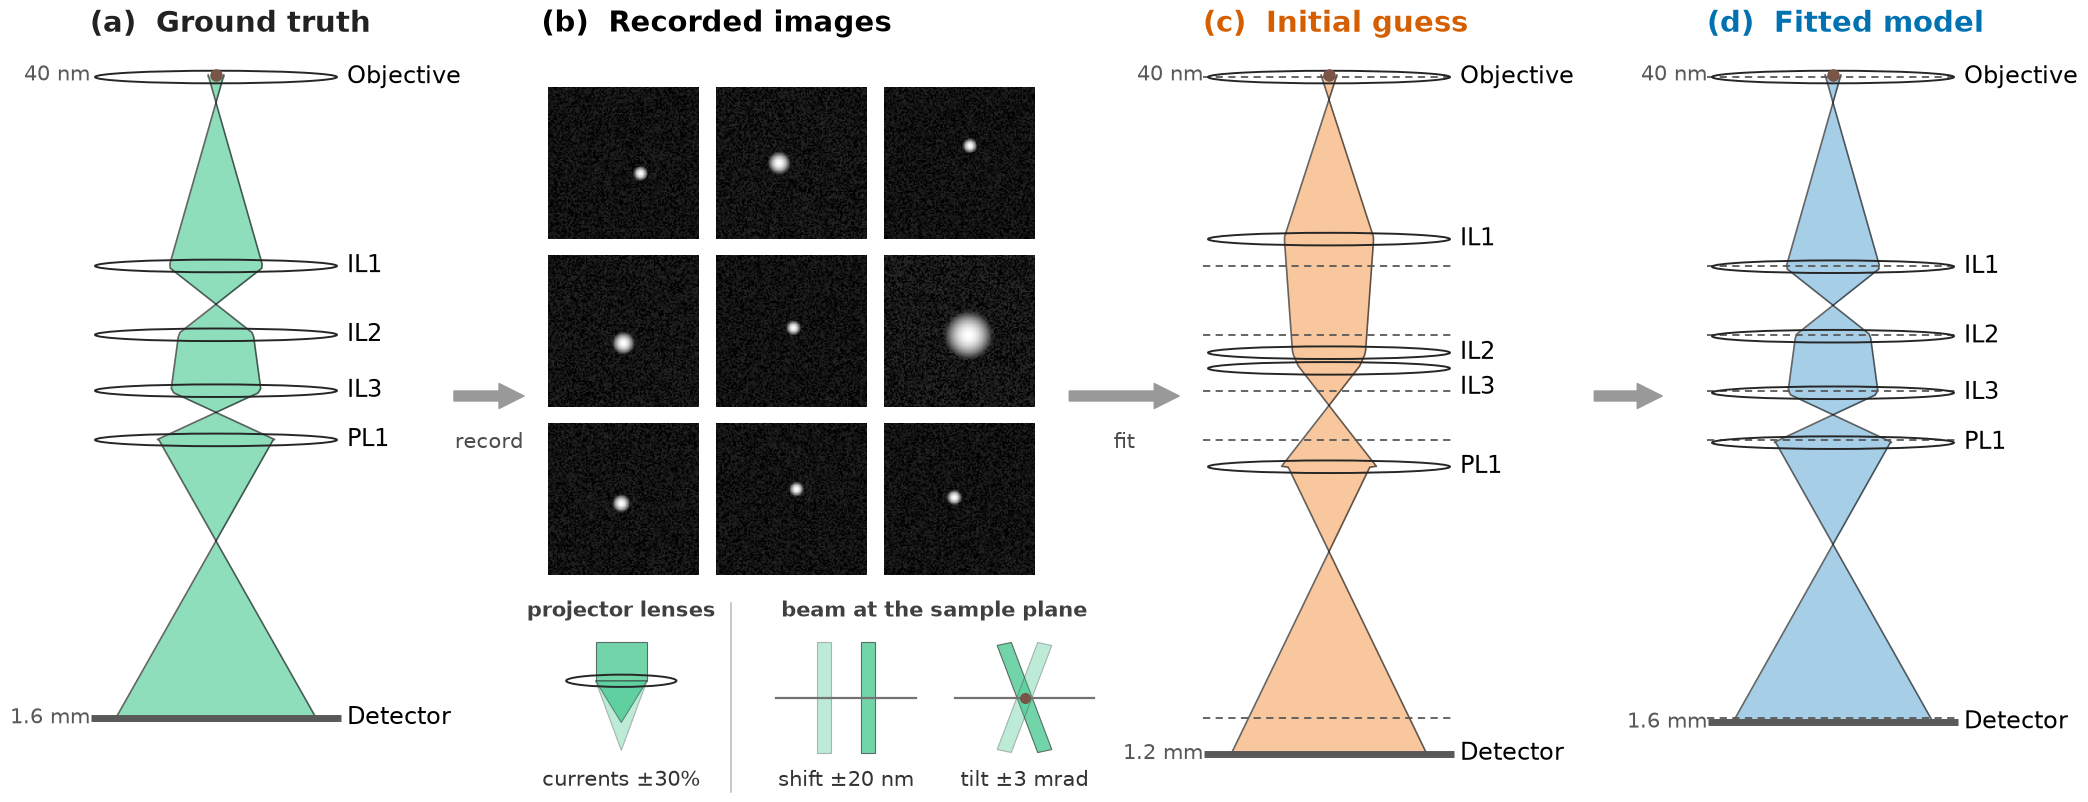

In [7]:
from matplotlib.figure import Figure

figure = Figure(figsize=(21, 9))
pi.draw_overview(figure, pi.Experiment(experiment), guess="Poor positions")
figure.savefig("figures/projector_inversion_overview.pdf")
figure.savefig("figures/projector_inversion_overview.png", dpi=300)
figure

**6. Ray diagrams for one image.** One recorded image and the same kicked beam traced through the ground truth, initial guess and fitted projector.

- **(a)** The recorded beam, with the measured centre and the centres predicted by the initial guess and the fit. An arrow points to a prediction outside the view.
- **(b–d)** Ray diagrams drawn as in the calibration browser. All three share the z window and one transverse scale wide enough for every model's beam, so a guess that lands elsewhere is seen doing so; dashed grey lines mark the true lens and detector planes.
- The heading gives the voltage, each lens current's change from the imaging setting, and the specimen kick.

Choose the image and the initial guess with the controls; **Save PDF** writes `figures/projector_inversion.pdf` and `.png`.

In [8]:
pi.figure_browser(experiment)

In [9]:
from matplotlib.figure import Figure

figure = Figure(figsize=(18, 7.6), layout="constrained")
pi.draw_figure(figure, pi.Experiment(experiment), voltage=0, setting=17, steering="Tilt X", view=1,
               guess="Poor positions")
figure.savefig("figures/projector_inversion.pdf")
figure.savefig("figures/projector_inversion.png", dpi=300)